# Lab L6-2：用中文搜尋商品照（D6-2）

**需求單 #D6-2**（虛構公司：曜嶼電子，電商部）：一萬張沒有標籤的商品照，顧客用中文搜尋。

今天用課程的 40 張示範商品照（8 類 × 5 張，**由 Stable Diffusion 1.5 生成**，不是真實商品）。

| 部分 | 做什麼 | 輸出 |
|---|---|---|
| 1 | 下載商品照；兩個模型：英文 CLIP vs 多語 SigLIP 2 | — |
| 2 | 零樣本標籤：用「一張○○的照片」當類別 | 標籤正確率 |
| 3 | 以文搜圖：繁中查詢 → cosine 相似度 → 前 5 名 | precision@5 |
| 4 | VLM 寫繁中替代文字（alt-text） | 說明文字、簡體字檢查 |
| 5 | 交付：Gradio 搜尋 App | 介面 |

執行階段：**T4 GPU**（第 4 部分的 VLM 需要；1～3 部分 CPU 也可以）。

torch 2.14.1+cu130 | transformers 5.22.1 | python 3.13.16
40 張商品照；類別： ['耳機', '行動電源', '智慧手錶', '掃地機器人', '電熱水壺', '筆電', '背包', '馬克杯']


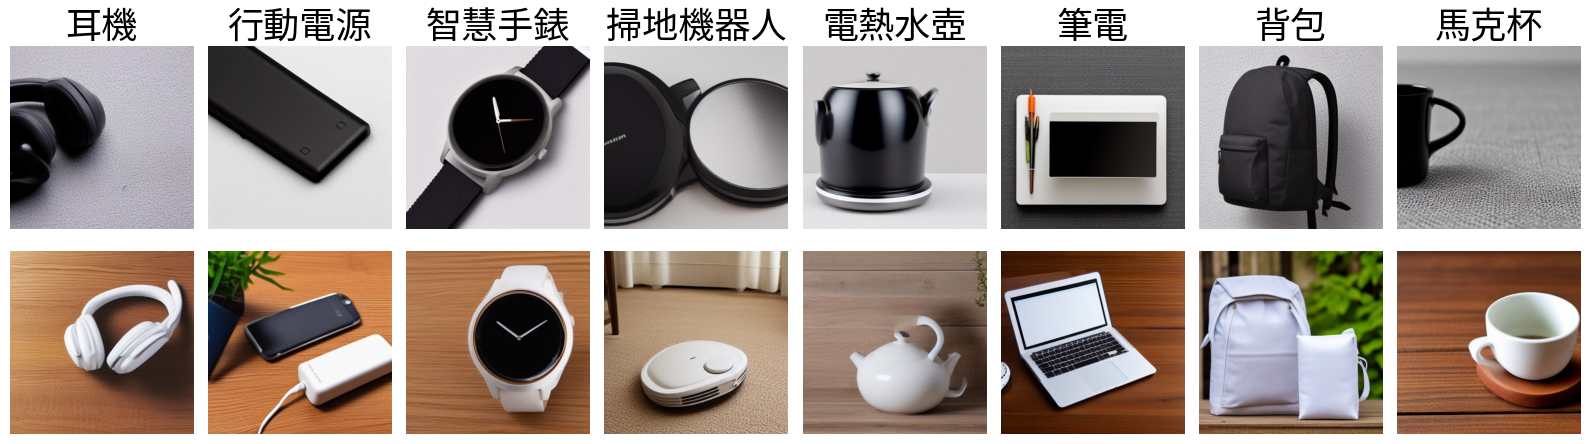

In [1]:
# 第 1 格：環境
%pip install -q opencc-python-reimplemented gradio
import os, io, csv, time, platform, glob, subprocess, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch, transformers
from PIL import Image
from matplotlib import font_manager
NOTO = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if not glob.glob(NOTO) and platform.system() == "Linux":
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True)
for f in glob.glob(NOTO):
    font_manager.fontManager.addfont(f)
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=f).get_name()
print("torch", torch.__version__, "| transformers", transformers.__version__, "| python", platform.python_version())
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

RAW = "https://raw.githubusercontent.com/LinTzuYu0925/GAI_tutorial/day6-done/22-catalog-search/materials/data"
def fetch_bytes(path):
    local = os.environ.get("LAB_DATA_DIR")          # 只有講師本機測試會設定
    if local:
        return open(os.path.join(local, path), "rb").read()
    return urllib.request.urlopen(f"{RAW}/{path}").read()

rows = list(csv.DictReader(io.StringIO(fetch_bytes("catalog.csv").decode("utf-8"))))
images = [Image.open(io.BytesIO(fetch_bytes("catalog/" + r["file"]))).convert("RGB") for r in rows]
CATS = list(dict.fromkeys(r["category"] for r in rows))
print(len(images), "張商品照；類別：", CATS)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
for col, c in enumerate(CATS):
    idx = [i for i, r in enumerate(rows) if r["category"] == c][:2]
    for row_, i in enumerate(idx):
        axes[row_, col].imshow(images[i]); axes[row_, col].axis("off")
    axes[0, col].set_title(c, fontsize=26)
plt.tight_layout(); plt.savefig("catalog_grid.png", dpi=110); plt.show()

## 1. 兩個模型：英文 CLIP vs 多語 SigLIP 2
兩個都是 D4-2 學過的「對比學習」：圖片和文字放進同一個空間，對的配對靠近、錯的配對遠離。
差別在**文字那一半**懂不懂中文。

In [2]:
from transformers import AutoModel, AutoProcessor
MODELS = {"CLIP（英文）": "openai/clip-vit-base-patch32", "SigLIP 2（多語）": "google/siglip2-base-patch16-224"}
loaded = {}
for name, mid in MODELS.items():
    m = AutoModel.from_pretrained(mid, dtype=dtype).to(device).eval()
    loaded[name] = (m, AutoProcessor.from_pretrained(mid), mid)

def _feat(out):
    return out if torch.is_tensor(out) else out.pooler_output

@torch.no_grad()
def embed_images(name, imgs):
    m, p, _ = loaded[name]
    x = p(images=imgs, return_tensors="pt").to(device)
    return torch.nn.functional.normalize(_feat(m.get_image_features(pixel_values=x["pixel_values"].to(dtype))).float(), dim=-1)

@torch.no_grad()
def embed_texts(name, texts):
    m, p, mid = loaded[name]
    kw = dict(padding="max_length", max_length=64) if "siglip" in mid else dict(padding=True)
    t = p(text=texts, return_tensors="pt", **kw).to(device)
    return torch.nn.functional.normalize(_feat(m.get_text_features(**t)).float(), dim=-1)

print("「耳機」被切成：")
for name, (m, p, mid) in loaded.items():
    print(f"  {name}：", p.tokenizer.tokenize("一副耳機"))

IMG = {name: embed_images(name, images) for name in loaded}
print({k: tuple(v.shape) for k, v in IMG.items()})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (14 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

「耳機」被切成：
  CLIP（英文）： ['ä¸', 'Ģ', 'å', 'ī', '¯', 'è', 'Ģ', '³', 'æ', '©', 'Ł</w>']
  SigLIP 2（多語）： ['一副', '耳', '機']
{'CLIP（英文）': (40, 512), 'SigLIP 2（多語）': (40, 768)}


## 2. 零樣本標籤：類別寫成一句話
不用訓練分類器：把 8 個類別寫成「一張○○的照片」，每張圖選最像的那一句。

In [3]:
LABEL_TEXT = [f"一張{c}的照片" for c in CATS]
gold = np.array([CATS.index(r["category"]) for r in rows])
TAG_ACC = {}
for name in loaded:
    T = embed_texts(name, LABEL_TEXT)
    pred = (IMG[name] @ T.T).argmax(-1).cpu().numpy()
    TAG_ACC[name] = (pred == gold).mean()
    print(f"{name}：零樣本標籤正確率 {TAG_ACC[name]:.0%}")
    wrong = [(rows[i]["file"], rows[i]["category"], CATS[pred[i]]) for i in range(len(rows)) if pred[i] != gold[i]]
    print("   標錯的例子：", wrong[:4])

CLIP（英文）：零樣本標籤正確率 22%
   標錯的例子： [('c0_0.jpg', '耳機', '行動電源'), ('c0_1.jpg', '耳機', '行動電源'), ('c0_2.jpg', '耳機', '行動電源'), ('c0_3.jpg', '耳機', '行動電源')]
SigLIP 2（多語）：零樣本標籤正確率 82%
   標錯的例子： [('c1_4.jpg', '行動電源', '筆電'), ('c3_0.jpg', '掃地機器人', '行動電源'), ('c3_2.jpg', '掃地機器人', '耳機'), ('c3_3.jpg', '掃地機器人', '智慧手錶')]


## 3. 以文搜圖：繁中查詢 → 前 5 名
搜尋＝把查詢句也變成向量，和 40 張圖算 cosine 相似度，排序取前 k 名。
**precision@5**：前 5 名裡，有幾張是對的類別。

In [4]:
QUERIES = {  # 查詢句 → 正確類別
    "可以聽音樂的耳機": "耳機",
    "幫手機充電的行動電源": "行動電源",
    "戴在手上的智慧手錶": "智慧手錶",
    "會自己打掃地板的機器人": "掃地機器人",
    "燒開水的水壺": "電熱水壺",
    "辦公用的筆記型電腦": "筆電",
    "上學背的包包": "背包",
    "喝咖啡的杯子": "馬克杯",
}

def search(name, query, k=5):
    q = embed_texts(name, [query])
    scores = (IMG[name] @ q.T).squeeze(-1)
    top = torch.topk(scores, k)
    return top.indices.tolist(), top.values.tolist()

def precision_at_k(retrieved, relevant_cat, k=5):
    return sum(rows[i]["category"] == relevant_cat for i in retrieved[:k]) / k

P5 = {}
for name in loaded:
    ps = []
    for q, cat in QUERIES.items():
        idx, _ = search(name, q)
        ps.append(precision_at_k(idx, cat))
    P5[name] = float(np.mean(ps))
    print(f"{name}：平均 precision@5 ＝ {P5[name]:.2f}")

CLIP（英文）：平均 precision@5 ＝ 0.20
SigLIP 2（多語）：平均 precision@5 ＝ 0.82


/tmp/ipykernel_517/1815814156.py:11: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.savefig("search_top5.png", dpi=110); plt.show()
/tmp/ipykernel_517/1815814156.py:11: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Noto Sans CJK JP.
  plt.tight_layout(); plt.savefig("search_top5.png", dpi=110); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Noto Sans CJK JP.
  fig.canvas.print_figure(bytes_io, **kw)


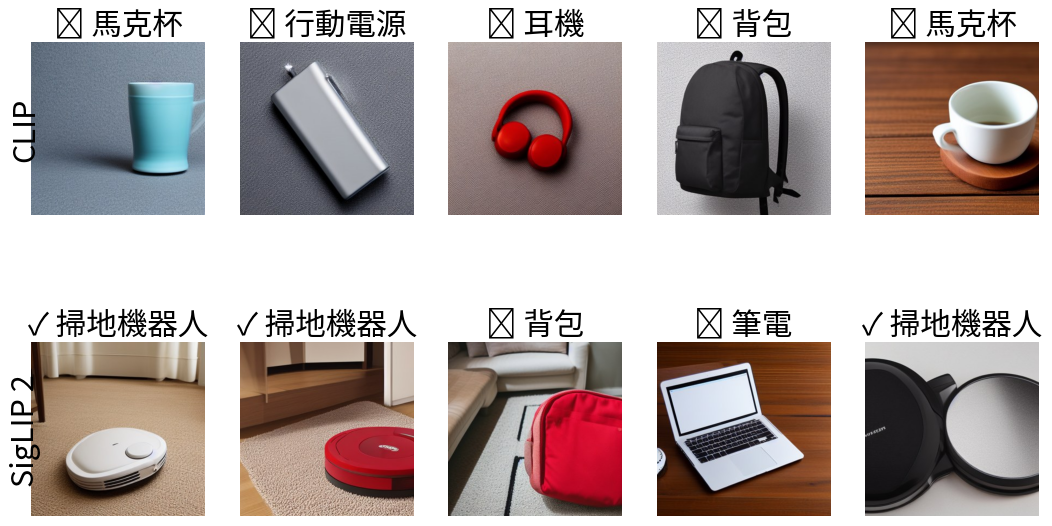

In [5]:
# 看一個查詢的前 5 名（兩個模型並排）
Q = "會自己打掃地板的機器人"
fig, axes = plt.subplots(2, 5, figsize=(13, 6.8), gridspec_kw={"hspace": 0.35})
for r_, name in enumerate(loaded):
    idx, sc = search(name, Q)
    for c_, (i, s) in enumerate(zip(idx, sc)):
        axes[r_, c_].imshow(images[i]); axes[r_, c_].axis("off")
        ok = "✓" if rows[i]["category"] == QUERIES[Q] else "✗"
        axes[r_, c_].set_title(f"{ok} {rows[i]['category']}", fontsize=22)
    axes[r_, 0].text(-40, 160, name.split("（")[0], rotation=90, va="center", fontsize=22)
plt.tight_layout(); plt.savefig("search_top5.png", dpi=110); plt.show()

## 4. VLM 寫繁中替代文字（alt-text）
VLM（視覺語言模型）：圖片切成小塊變成 token，放在問題前面，一起做 D5-2 的接龍。
替代文字給看不到圖的人（螢幕報讀）和搜尋引擎用。**檢查簡體字**（D5-4 的老問題）。

In [6]:
from opencc import OpenCC
_to_tw, _to_s = OpenCC("s2tw"), OpenCC("t2s")
TW_OK = set("台里后干只系才面伙")
# 大陸用語（左）→ 台灣用語（右）：字是繁體，用語不一定是台灣的
MAINLAND = {"音頻": "音訊", "視頻": "影片", "質量": "品質", "屏幕": "螢幕", "軟件": "軟體", "信息": "資訊"}
def simplified_chars(text):
    return [c for c in text if c not in TW_OK and _to_tw.convert(c) != c and _to_s.convert(c) == c]

N_ALT = 8 if device == "cuda" else 2
ALT = []
try:
    from transformers import AutoModelForImageTextToText
    VLM = "Qwen/Qwen2-VL-2B-Instruct"
    vp = AutoProcessor.from_pretrained(VLM, min_pixels=224 * 224, max_pixels=320 * 320)
    vlm = AutoModelForImageTextToText.from_pretrained(VLM, dtype=dtype).to(device).eval()
    ASK = "請用繁體中文（台灣用語）寫一句 30 字以內的商品圖片說明，給網站的替代文字使用。"
    for i in range(0, 40, 40 // N_ALT)[:N_ALT]:
        msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": ASK}]}]
        prompt = vp.apply_chat_template(msgs, add_generation_prompt=True)
        x = vp(text=[prompt], images=[images[i]], return_tensors="pt").to(device)
        t0 = time.time()
        with torch.no_grad():
            out = vlm.generate(**x, max_new_tokens=60, do_sample=False)
        alt = vp.batch_decode(out[:, x["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()
        terms = [f"{k}→{v}" for k, v in MAINLAND.items() if k in alt]
        ALT.append((rows[i]["file"], rows[i]["category"], alt, "".join(simplified_chars(alt)), terms))
        print(f"{rows[i]['file']}（{rows[i]['category']}，{time.time()-t0:.1f} 秒）：{alt}｜簡體字：{''.join(simplified_chars(alt)) or '無'}｜大陸用語：{terms or '無'}")
    print("含簡體字的說明：", sum(bool(a[3]) for a in ALT), "/", len(ALT), "；含大陸用語：", sum(bool(a[4]) for a in ALT), "/", len(ALT))
except Exception as e:
    print("VLM 沒有成功（記憶體、版本或下載問題）：", type(e).__name__, e)

preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (4 outputs left out)

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


c0_0.jpg（耳機，1.9 秒）：黑色頭戴式耳機，適用於各種音頻設備。｜簡體字：無｜大陸用語：['音頻→音訊']
c1_0.jpg（行動電源，0.7 秒）：這是一款黑色的遙控器，設計簡潔，功能強大。｜簡體字：無｜大陸用語：無
c2_0.jpg（智慧手錶，2.0 秒）：簡約時尚，時尚設計，黑色錶帶，時尚風格，簡約風格，時尚設計，時尚風格，時尚設計，時尚風格，時尚設計，時尚風格，時尚設計，時尚風格，時尚設計，時尚｜簡體字：無｜大陸用語：無
c3_0.jpg（掃地機器人，0.8 秒）：這是一款黑色的摺疊式鏡子，鏡面光滑，方便攜帶。｜簡體字：無｜大陸用語：無
c4_0.jpg（電熱水壺，0.7 秒）：黑色電熱壺，適用於電熱壺底座，方便使用。｜簡體字：無｜大陸用語：無
c5_0.jpg（筆電，1.6 秒）：這是一款專為設計師和創意人士設計的平板，具有高分辨率和高精度的繪圖功能，適合進行各種設計和繪畫工作。｜簡體字：無｜大陸用語：無
c6_0.jpg（背包，0.8 秒）：黑色後背包，容量大，設計簡約，適合日常使用。｜簡體字：無｜大陸用語：無
c7_0.jpg（馬克杯，0.8 秒）：黑色陶瓷杯，簡約設計，適用於餐飲、茶歇等場合。｜簡體字：無｜大陸用語：無
含簡體字的說明： 0 / 8 ；含大陸用語： 1 / 8


## 5. 交付：Gradio 搜尋 App
用 SigLIP 2：輸入一句繁中，回傳前 5 張圖。

In [7]:
import gradio as gr
def app(query):
    idx, sc = search("SigLIP 2（多語）", query)
    return [(images[i], f"{rows[i]['category']}（{s:.2f}）") for i, s in zip(idx, sc)]
demo = gr.Interface(fn=app, inputs=gr.Textbox(label="用中文搜尋商品"), outputs=gr.Gallery(label="前 5 名", columns=5),
                    title="曜嶼商品照搜尋（示範：AI 生成的商品照）", examples=[[q] for q in list(QUERIES)[:3]])
if not os.environ.get("LAB_NO_LAUNCH"):
    demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fdeac1cee22939600b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
